# Beam-Width Sensitivity on Extended Benchmarks

This notebook compares the allocation + tree heuristic with final tree beam widths \(B=1\), \(B=3\), and \(B=5\) on the extended benchmark data sets. The allocation descent settings are fixed across beam widths, so the comparison isolates the effect of the final beam-search tree construction.

In [7]:
from pathlib import Path
import importlib
import sys

from IPython.display import Markdown, display


def find_project_directory(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "src" / "heuristic.py").is_file() and (candidate / "inputs").is_dir():
            return candidate
        nested = candidate / "min-error-sequential"
        if (nested / "src" / "heuristic.py").is_file() and (nested / "inputs").is_dir():
            return nested
    raise RuntimeError("Could not locate the min-error-sequential project directory")


PROJECT_DIRECTORY = find_project_directory(Path.cwd())
SOURCE_DIRECTORY = PROJECT_DIRECTORY / "src"
if str(SOURCE_DIRECTORY) not in sys.path:
    sys.path.insert(0, str(SOURCE_DIRECTORY))

import heuristic
heuristic = importlib.reload(heuristic)

import beam_width_analysis
beam_width_analysis = importlib.reload(beam_width_analysis)

print("Project directory:", PROJECT_DIRECTORY)
print("Source directory:", SOURCE_DIRECTORY)

Project directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential
Source directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/src


## Settings

`RUN_SCOPE = "test"` evaluates one replicate per field family, \(K\), and \(M\) cell. `RUN_SCOPE = "full"` evaluates all extended benchmark records. Set `RUN_STUDY = True` to compute and save the comparison; leave it as `False` to load existing saved results.

In [8]:
DATASETS = ("benchmark_1d", "benchmark_2d")
BEAM_WIDTHS = (1, 3, 5)

RUN_SCOPE = "full"  # switch to "full" for all extended records
RUN_STUDY = True

if RUN_SCOPE not in {"test", "full"}:
    raise ValueError('RUN_SCOPE must be "test" or "full"')

REPLICATES_PER_CELL = 1 if RUN_SCOPE == "test" else None
K_VALUES = None
M_VALUES = None
RANDOM_CASES_PER_K_M = None

RESULTS_ROOT = PROJECT_DIRECTORY / "results" / "beam_width"
PROGRESS_EVERY = 25

HEURISTIC_SETTINGS = {
    "max_iterations": 30,
    "improvement_threshold": 0.0,
    "initialization": "near_uniform",
    "random_seed": 0,
    "include_greedy_start": False,
    "move_sizes": (1, 2, 3),
}

print("Run scope:", RUN_SCOPE)
print("Run study:", RUN_STUDY)
print("Datasets:", DATASETS)
print("Beam widths:", BEAM_WIDTHS)
print("Results directory:", RESULTS_ROOT)
print("Heuristic settings:", HEURISTIC_SETTINGS)

Run scope: full
Run study: True
Datasets: ('benchmark_1d', 'benchmark_2d')
Beam widths: (1, 3, 5)
Results directory: /Users/avishka/Academic/PhD/Research/QSN Research/Repos/quantum-sensor-placement-research/min-error-sequential/results/beam_width
Heuristic settings: {'max_iterations': 30, 'improvement_threshold': 0.0, 'initialization': 'near_uniform', 'random_seed': 0, 'include_greedy_start': False, 'move_sizes': (1, 2, 3)}


## Run or Load Results

The saved tables are stored under `results/beam_width`. If the requested scope has not been generated yet, set `RUN_STUDY = True` and rerun this section.

In [9]:
def load_or_run_dataset(dataset):
    if RUN_STUDY:
        return beam_width_analysis.run_beam_width_study(
            dataset,
            beam_widths=BEAM_WIDTHS,
            replicates_per_cell=REPLICATES_PER_CELL,
            results_root=RESULTS_ROOT,
            progress_every=PROGRESS_EVERY,
            k_values=K_VALUES,
            m_values=M_VALUES,
            random_cases_per_k_m=RANDOM_CASES_PER_K_M,
            **HEURISTIC_SETTINGS,
        )
    return beam_width_analysis.load_beam_width_results(
        dataset,
        results_root=RESULTS_ROOT,
        run_scope=RUN_SCOPE,
    )


records_by_dataset = {}
missing_datasets = []
for dataset in DATASETS:
    display(Markdown(f"### {dataset}"))
    try:
        records_by_dataset[dataset] = load_or_run_dataset(dataset)
    except FileNotFoundError:
        missing_datasets.append(dataset)
        records_by_dataset[dataset] = []
        print(
            f"{dataset}: no saved beam-width results for scope '{RUN_SCOPE}'. "
            "Set RUN_STUDY = True and rerun this section to generate them."
        )
        continue
    print(f"{dataset}: {len(records_by_dataset[dataset])} beam-width records")

available_records_by_dataset = {
    dataset: records for dataset, records in records_by_dataset.items() if records
}
if missing_datasets and not RUN_STUDY:
    display(Markdown(
        "No saved results were found for "
        + ", ".join(f"`{dataset}`" for dataset in missing_datasets)
        + f" with `RUN_SCOPE = {RUN_SCOPE!r}`. Set `RUN_STUDY = True` to generate them."
    ))


### benchmark_1d

benchmark_1d: completed case 1/2700 (gaussian, K=3, M=3)
benchmark_1d: completed case 25/2700 (gaussian, K=3, M=3)
benchmark_1d: completed case 50/2700 (gaussian, K=3, M=4)
benchmark_1d: completed case 75/2700 (gaussian, K=3, M=5)
benchmark_1d: completed case 100/2700 (gaussian, K=3, M=6)
benchmark_1d: completed case 125/2700 (gaussian, K=3, M=7)
benchmark_1d: completed case 150/2700 (gaussian, K=3, M=7)
benchmark_1d: completed case 175/2700 (gaussian, K=3, M=8)
benchmark_1d: completed case 200/2700 (gaussian, K=4, M=3)
benchmark_1d: completed case 225/2700 (gaussian, K=4, M=4)
benchmark_1d: completed case 250/2700 (gaussian, K=4, M=5)
benchmark_1d: completed case 275/2700 (gaussian, K=4, M=6)
benchmark_1d: completed case 300/2700 (gaussian, K=4, M=6)
benchmark_1d: completed case 325/2700 (gaussian, K=4, M=7)
benchmark_1d: completed case 350/2700 (gaussian, K=4, M=8)
benchmark_1d: completed case 375/2700 (gaussian, K=5, M=3)
benchmark_1d: completed case 400/2700 (gaussian, K=5, M=4)
be

### benchmark_2d

benchmark_2d: completed case 1/2700 (gaussian, K=3, M=3)
benchmark_2d: completed case 25/2700 (gaussian, K=3, M=3)
benchmark_2d: completed case 50/2700 (gaussian, K=3, M=4)
benchmark_2d: completed case 75/2700 (gaussian, K=3, M=5)
benchmark_2d: completed case 100/2700 (gaussian, K=3, M=6)
benchmark_2d: completed case 125/2700 (gaussian, K=3, M=7)
benchmark_2d: completed case 150/2700 (gaussian, K=3, M=7)
benchmark_2d: completed case 175/2700 (gaussian, K=3, M=8)
benchmark_2d: completed case 200/2700 (gaussian, K=4, M=3)
benchmark_2d: completed case 225/2700 (gaussian, K=4, M=4)
benchmark_2d: completed case 250/2700 (gaussian, K=4, M=5)
benchmark_2d: completed case 275/2700 (gaussian, K=4, M=6)
benchmark_2d: completed case 300/2700 (gaussian, K=4, M=6)
benchmark_2d: completed case 325/2700 (gaussian, K=4, M=7)
benchmark_2d: completed case 350/2700 (gaussian, K=4, M=8)
benchmark_2d: completed case 375/2700 (gaussian, K=5, M=3)
benchmark_2d: completed case 400/2700 (gaussian, K=5, M=4)
be

## Numerical Summaries

The first table summarizes each beam width over all selected extended cases and budget levels. The second table reports the budget-level means used by the comparison plot.

In [15]:
from statistics import mean


def as_float(row, key):
    return float(row[key])


def first_float(row, *keys):
    for key in keys:
        if key in row:
            return float(row[key])
    raise KeyError(keys[0])


def markdown_table(rows, columns, formatters=None):
    formatters = formatters or {}
    header = "| " + " | ".join(label for label, _ in columns) + " |"
    separator = "| " + " | ".join("---" for _ in columns) + " |"
    lines = [header, separator]
    for row in rows:
        values = []
        for _, key in columns:
            value = row[key]
            formatter = formatters.get(key, str)
            values.append(formatter(value))
        lines.append("| " + " | ".join(values) + " |")
    return "\n".join(lines)


def budget_summary(records_by_dataset):
    rows = []
    for dataset, records in records_by_dataset.items():
        if not records:
            continue
        dimension = f"{int(records[0]['spatial_dimension'])}D"
        for beam_width in BEAM_WIDTHS:
            beam_records = [
                record for record in records
                if int(record["beam_width"]) == beam_width
            ]
            if not beam_records:
                continue
            for budget_level in sorted({int(record["budget_level"]) for record in beam_records}):
                selected = [
                    record for record in beam_records
                    if int(record["budget_level"]) == budget_level
                ]
                budget_ratio = mean(
                    first_float(row, "budget_ratio", "budget_fraction_of_N_min")
                    for row in selected
                )
                mean_error = mean(as_float(row, "heuristic_error") for row in selected)
                mean_seconds = mean(
                    first_float(row, "elapsed_seconds", "heuristic_seconds")
                    for row in selected
                )
                rows.append({
                    "dataset": dataset,
                    "dimension": dimension,
                    "beam_width": beam_width,
                    "budget_level": budget_level,
                    "budget_ratio": budget_ratio,
                    "mean_budget_ratio": budget_ratio,
                    "runs": len(selected),
                    "mean_error": mean_error,
                    "mean_surrogate_error": mean_error,
                    "mean_seconds": mean_seconds,
                })
    return rows


budget_rows = budget_summary(available_records_by_dataset)
if budget_rows:
    display(Markdown("### Mean error by budget and beam width"))
    display(Markdown(markdown_table(
        budget_rows,
        (
            ("Dimension", "dimension"),
            ("Beam width", "beam_width"),
            ("Budget level", "budget_level"),
            ("Budget ratio", "budget_ratio"),
            ("Runs", "runs"),
            ("Mean error", "mean_error"),
            ("Mean seconds", "mean_seconds"),
        ),
        {
            "beam_width": lambda x: f"{int(float(x))}",
            "budget_level": lambda x: f"{int(float(x))}",
            "budget_ratio": lambda x: f"{float(x):.3f}",
            "runs": lambda x: f"{int(float(x))}",
            "mean_error": lambda x: f"{float(x):.4f}",
            "mean_seconds": lambda x: f"{float(x):.3f}",
        },
    )))
else:
    display(Markdown("No beam-width results are available for the selected scope."))


### Mean error by budget and beam width

| Dimension | Beam width | Budget level | Budget ratio | Runs | Mean error | Mean seconds |
| --- | --- | --- | --- | --- | --- | --- |
| 1D | 1 | 1 | 0.166 | 2700 | 0.3358 | 0.007 |
| 1D | 1 | 2 | 0.315 | 2700 | 0.1734 | 0.011 |
| 1D | 1 | 3 | 0.471 | 2692 | 0.0969 | 0.014 |
| 1D | 1 | 4 | 0.602 | 2636 | 0.0603 | 0.017 |
| 1D | 3 | 1 | 0.166 | 2700 | 0.3216 | 0.016 |
| 1D | 3 | 2 | 0.315 | 2700 | 0.1605 | 0.019 |
| 1D | 3 | 3 | 0.471 | 2692 | 0.0873 | 0.022 |
| 1D | 3 | 4 | 0.602 | 2636 | 0.0527 | 0.025 |
| 1D | 5 | 1 | 0.166 | 2700 | 0.3182 | 0.024 |
| 1D | 5 | 2 | 0.315 | 2700 | 0.1578 | 0.028 |
| 1D | 5 | 3 | 0.471 | 2692 | 0.0852 | 0.031 |
| 1D | 5 | 4 | 0.602 | 2636 | 0.0511 | 0.034 |
| 2D | 1 | 1 | 0.159 | 2700 | 0.3723 | 0.007 |
| 2D | 1 | 2 | 0.297 | 2700 | 0.2073 | 0.010 |
| 2D | 1 | 3 | 0.444 | 2695 | 0.1250 | 0.013 |
| 2D | 1 | 4 | 0.564 | 2637 | 0.0845 | 0.016 |
| 2D | 3 | 1 | 0.159 | 2700 | 0.3607 | 0.016 |
| 2D | 3 | 2 | 0.297 | 2700 | 0.1955 | 0.019 |
| 2D | 3 | 3 | 0.444 | 2695 | 0.1155 | 0.022 |
| 2D | 3 | 4 | 0.564 | 2637 | 0.0764 | 0.025 |
| 2D | 5 | 1 | 0.159 | 2700 | 0.3579 | 0.025 |
| 2D | 5 | 2 | 0.297 | 2700 | 0.1929 | 0.028 |
| 2D | 5 | 3 | 0.444 | 2695 | 0.1135 | 0.031 |
| 2D | 5 | 4 | 0.564 | 2637 | 0.0748 | 0.034 |

In [16]:
overall_rows = []
for dataset, records in available_records_by_dataset.items():
    dimension = f"{int(records[0]['spatial_dimension'])}D"
    for row in beam_width_analysis.beam_width_summary(records):
        overall_rows.append({"dataset": dataset, "dimension": dimension, **row})

if overall_rows:
    display(Markdown("### Overall Beam-Width Summary"))
    display(Markdown(markdown_table(
        overall_rows,
        (
            ("Dataset", "dataset"),
            ("Dimension", "dimension"),
            ("Beam width", "beam_width"),
            ("Runs", "runs"),
            ("Mean surrogate error", "mean_final_error"),
            ("Maximum surrogate error", "maximum_final_error"),
            ("Mean seconds", "mean_seconds"),
        ),
        {
            "beam_width": lambda value: f"{int(value)}",
            "runs": lambda value: f"{int(value)}",
            "mean_final_error": lambda value: f"{float(value):.5f}",
            "maximum_final_error": lambda value: f"{float(value):.5f}",
            "mean_seconds": lambda value: f"{float(value):.4f}",
        },
    )))
else:
    display(Markdown("No overall summary was generated because no beam-width results are available."))


### Overall Beam-Width Summary

| Dataset | Dimension | Beam width | Runs | Mean surrogate error | Maximum surrogate error | Mean seconds |
| --- | --- | --- | --- | --- | --- | --- |
| benchmark_1d | 1D | 1 | 10728 | 0.16728 | 0.71923 | 0.0120 |
| benchmark_1d | 1D | 3 | 10728 | 0.15619 | 0.71653 | 0.0205 |
| benchmark_1d | 1D | 5 | 10728 | 0.15373 | 0.71567 | 0.0294 |
| benchmark_2d | 2D | 1 | 10732 | 0.19798 | 0.77356 | 0.0119 |
| benchmark_2d | 2D | 3 | 10732 | 0.18771 | 0.77300 | 0.0203 |
| benchmark_2d | 2D | 5 | 10732 | 0.18545 | 0.77287 | 0.0293 |

In [17]:
budget_rows = budget_summary(available_records_by_dataset)

if budget_rows:
    display(Markdown("### Budget-Level Summary"))
    display(Markdown(markdown_table(
        budget_rows,
        (
            ("Dataset", "dataset"),
            ("Dimension", "dimension"),
            ("Budget level", "budget_level"),
            ("Mean budget ratio", "mean_budget_ratio"),
            ("Beam width", "beam_width"),
            ("Runs", "runs"),
            ("Mean surrogate error", "mean_surrogate_error"),
            ("Mean seconds", "mean_seconds"),
        ),
        {
            "budget_level": lambda value: f"{int(value)}",
            "mean_budget_ratio": lambda value: f"{float(value):.3f}",
            "beam_width": lambda value: f"{int(value)}",
            "runs": lambda value: f"{int(value)}",
            "mean_surrogate_error": lambda value: f"{float(value):.5f}",
            "mean_seconds": lambda value: f"{float(value):.4f}",
        },
    )))
else:
    display(Markdown("No budget-level summary was generated because no beam-width results are available."))


### Budget-Level Summary

| Dataset | Dimension | Budget level | Mean budget ratio | Beam width | Runs | Mean surrogate error | Mean seconds |
| --- | --- | --- | --- | --- | --- | --- | --- |
| benchmark_1d | 1D | 1 | 0.166 | 1 | 2700 | 0.33585 | 0.0074 |
| benchmark_1d | 1D | 2 | 0.315 | 1 | 2700 | 0.17338 | 0.0106 |
| benchmark_1d | 1D | 3 | 0.471 | 1 | 2692 | 0.09689 | 0.0137 |
| benchmark_1d | 1D | 4 | 0.602 | 1 | 2636 | 0.06025 | 0.0166 |
| benchmark_1d | 1D | 1 | 0.166 | 3 | 2700 | 0.32164 | 0.0157 |
| benchmark_1d | 1D | 2 | 0.315 | 3 | 2700 | 0.16045 | 0.0190 |
| benchmark_1d | 1D | 3 | 0.471 | 3 | 2692 | 0.08729 | 0.0221 |
| benchmark_1d | 1D | 4 | 0.602 | 3 | 2636 | 0.05270 | 0.0253 |
| benchmark_1d | 1D | 1 | 0.166 | 5 | 2700 | 0.31817 | 0.0245 |
| benchmark_1d | 1D | 2 | 0.315 | 5 | 2700 | 0.15780 | 0.0278 |
| benchmark_1d | 1D | 3 | 0.471 | 5 | 2692 | 0.08518 | 0.0310 |
| benchmark_1d | 1D | 4 | 0.602 | 5 | 2636 | 0.05114 | 0.0344 |
| benchmark_2d | 2D | 1 | 0.159 | 1 | 2700 | 0.37234 | 0.0073 |
| benchmark_2d | 2D | 2 | 0.297 | 1 | 2700 | 0.20734 | 0.0104 |
| benchmark_2d | 2D | 3 | 0.444 | 1 | 2695 | 0.12495 | 0.0134 |
| benchmark_2d | 2D | 4 | 0.564 | 1 | 2637 | 0.08451 | 0.0164 |
| benchmark_2d | 2D | 1 | 0.159 | 3 | 2700 | 0.36066 | 0.0157 |
| benchmark_2d | 2D | 2 | 0.297 | 3 | 2700 | 0.19553 | 0.0188 |
| benchmark_2d | 2D | 3 | 0.444 | 3 | 2695 | 0.11549 | 0.0219 |
| benchmark_2d | 2D | 4 | 0.564 | 3 | 2637 | 0.07643 | 0.0251 |
| benchmark_2d | 2D | 1 | 0.159 | 5 | 2700 | 0.35793 | 0.0246 |
| benchmark_2d | 2D | 2 | 0.297 | 5 | 2700 | 0.19290 | 0.0279 |
| benchmark_2d | 2D | 3 | 0.444 | 5 | 2695 | 0.11348 | 0.0306 |
| benchmark_2d | 2D | 4 | 0.564 | 5 | 2637 | 0.07477 | 0.0341 |

## Beam-Width Comparison Plot

The plot averages over the selected field families, \(K\) values, \(M\) values, and replicates at each budget level.

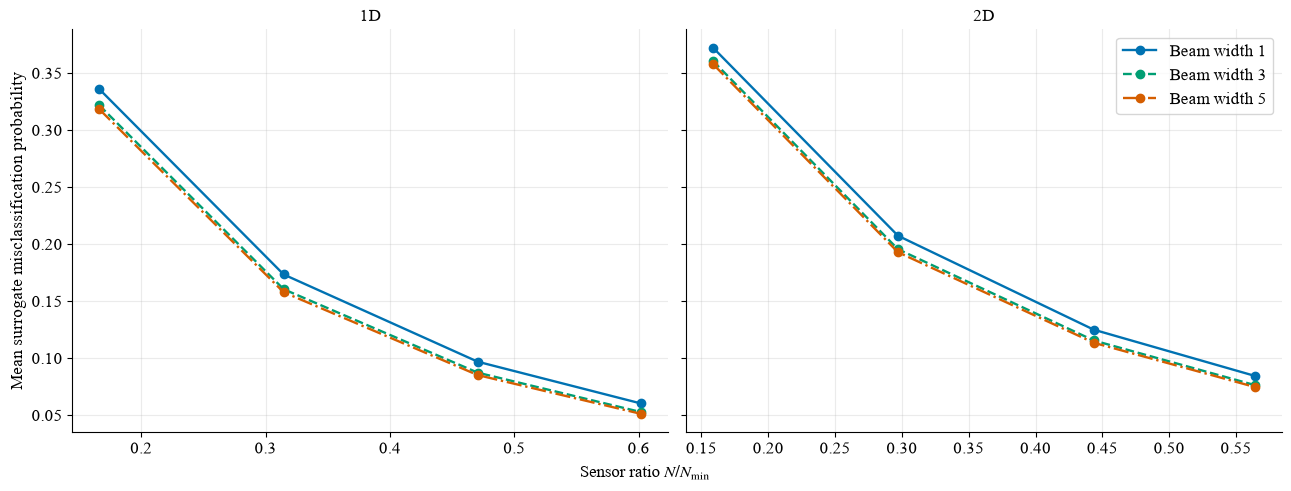

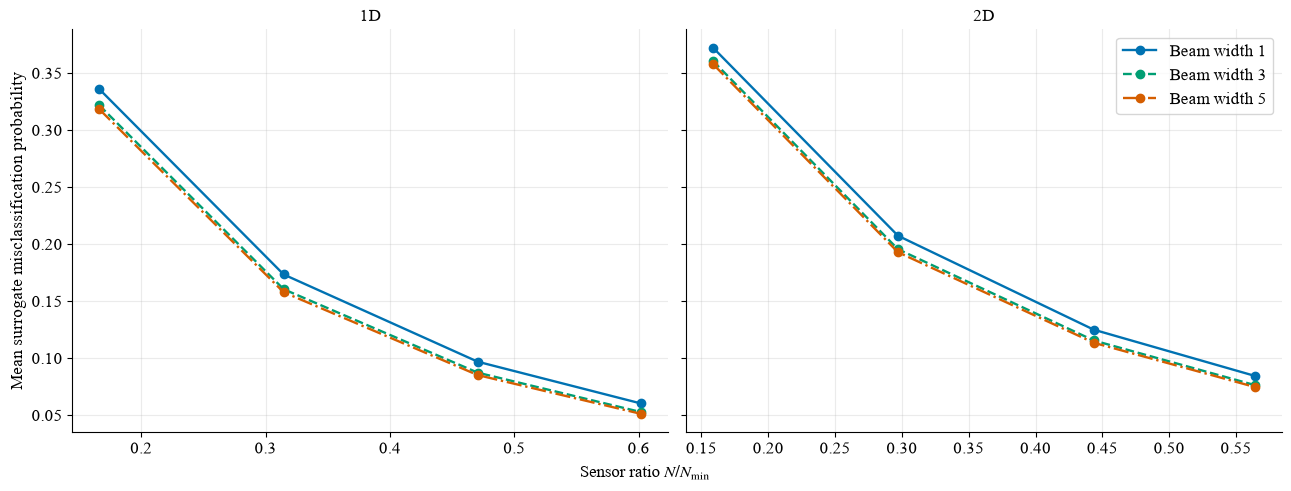

In [18]:
if available_records_by_dataset:
    figure = beam_width_analysis.make_beam_width_plot(
        available_records_by_dataset,
        results_root=RESULTS_ROOT,
        run_scope=RUN_SCOPE,
    )
    display(figure)
else:
    display(Markdown("No beam-width plot was generated because no saved results are available."))


## Saved Outputs

The detailed records and compact summaries are saved under `results/beam_width`. The combined comparison figure is saved under `results/beam_width/summary_beam_width_<scope>/figures`.